# Entrenamiento de detección de emociones con Eigenfaces + SVM

Importación de paquetes

In [6]:
import os

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
from joblib import Memory
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


Variables del dataset

In [2]:
DATASET_DIR = "dataset_processed"
IMG_SIZE = 32
MODEL_PATH = "model_results/svm/eigenfaces_svm.joblib"

CLASSES = sorted(os.listdir(os.path.join(DATASET_DIR, "train")))
print("Clases:", CLASSES)


Clases: ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']


Cargar imágenes (gris, 32x32) y combinarlas con los keypoints geométricos de MediaPipe

In [3]:
def load_split(split_name):
    keypoints_path = os.path.join(DATASET_DIR, f"{split_name}_keypoints.npz")
    kp_data = np.load(keypoints_path, allow_pickle=True)
    kp_features = kp_data["features"].astype(np.float32)
    kp_labels = kp_data["labels"]
    kp_filenames = kp_data["filenames"]

    split_dir = os.path.join(DATASET_DIR, split_name)

    X_pixels, y = [], []
    for label, fname in zip(kp_labels, kp_filenames):
        img = cv2.imread(os.path.join(split_dir, label, fname), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_pixels.append(img.flatten())
        y.append(label)

    X_pixels = np.array(X_pixels, dtype=np.float32)
    X = np.concatenate([X_pixels, kp_features], axis=1)
    return X, np.array(y)


X_train, y_train = load_split("train")
X_test, y_test = load_split("test")

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (36502, 1033) Test: (9182, 1033)


Entrenamiento

In [4]:
cache_dir = "pipeline_cache"
memory = Memory(location=cache_dir, verbose=0)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("svm", SVC()),
], memory=memory)

param_grid = {
    "pca__n_components": [50, 100, 150],
    "svm__C": [1, 10, 100],
    "svm__kernel": ["rbf"],
}

grid_search = GridSearchCV(pipeline, param_grid, cv=3, n_jobs=2, verbose=1)
grid_search.fit(X_train, y_train)

print("Mejores parámetros:", grid_search.best_params_)
print("Mejor accuracy en validación cruzada:", grid_search.best_score_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Mejores parámetros: {'pca__n_components': 150, 'svm__C': 100, 'svm__kernel': 'rbf'}
Mejor accuracy en validación cruzada: 0.8297623577036365


Guardar el modelo entrenado y generar una gráfica de los resultados

Modelo guardado en model_results/svm/eigenfaces_svm.joblib


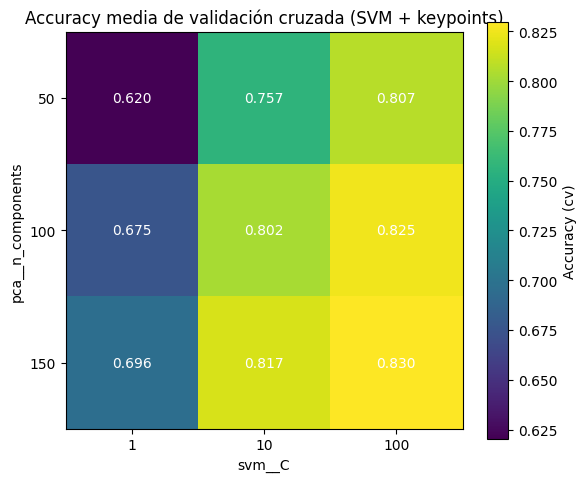

In [5]:
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
best_model = grid_search.best_estimator_
joblib.dump(best_model, MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH}")

n_components_values = sorted(set(grid_search.cv_results_["param_pca__n_components"]))
c_values = sorted(set(grid_search.cv_results_["param_svm__C"]))

scores = np.zeros((len(n_components_values), len(c_values)))
for i, n_comp in enumerate(n_components_values):
    for j, c_val in enumerate(c_values):
        mask = (grid_search.cv_results_["param_pca__n_components"] == n_comp) & (
            grid_search.cv_results_["param_svm__C"] == c_val
        )
        scores[i, j] = grid_search.cv_results_["mean_test_score"][mask][0]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(scores, cmap="viridis")

ax.set_xticks(range(len(c_values)))
ax.set_xticklabels(c_values)
ax.set_yticks(range(len(n_components_values)))
ax.set_yticklabels(n_components_values)
ax.set_xlabel("svm__C")
ax.set_ylabel("pca__n_components")
ax.set_title("Accuracy media de validación cruzada (SVM + keypoints)")

for i in range(len(n_components_values)):
    for j in range(len(c_values)):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="white")

fig.colorbar(im, ax=ax, label="Accuracy (cv)")
fig.tight_layout()
fig.savefig("model_results/svm/svm_training_results.png", dpi=150)
plt.show()

Evaluación en test y resultados por clase

Accuracy en test: 0.907536484426051
              precision    recall  f1-score   support

       Angry       0.86      0.89      0.88      1540
        Fear       0.86      0.83      0.85      1413
       Happy       0.95      0.96      0.95      3105
         Sad       0.89      0.87      0.88      1755
     Suprise       0.93      0.94      0.93      1369

    accuracy                           0.91      9182
   macro avg       0.90      0.90      0.90      9182
weighted avg       0.91      0.91      0.91      9182



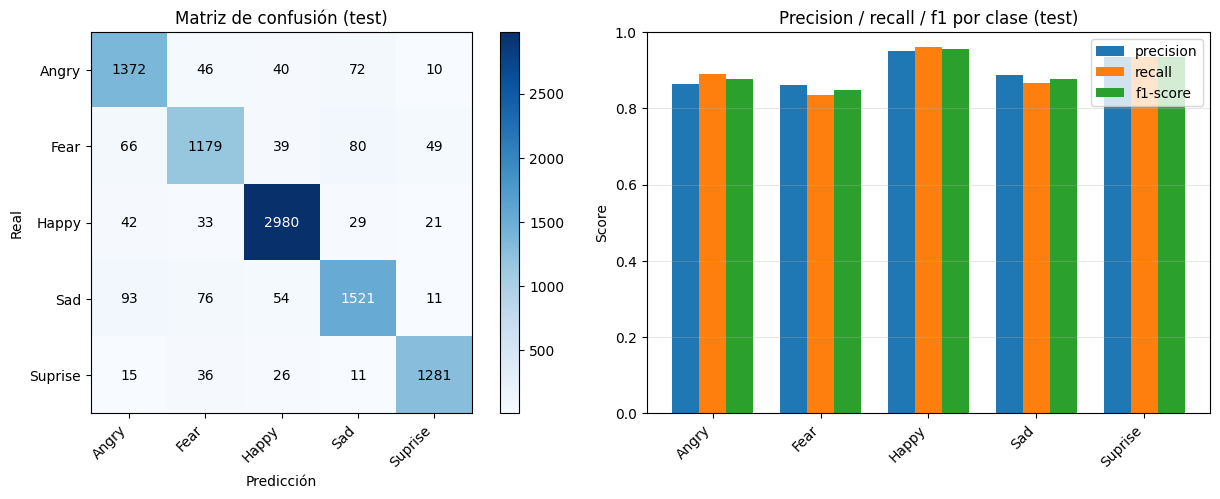

In [7]:
y_pred = best_model.predict(X_test)
test_accuracy = (y_pred == y_test).mean()
print("Accuracy en test:", test_accuracy)

report = classification_report(
    y_test, y_pred, labels=CLASSES, target_names=CLASSES, output_dict=True
)
print(classification_report(y_test, y_pred, labels=CLASSES, target_names=CLASSES))

cm = confusion_matrix(y_test, y_pred, labels=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks(range(len(CLASSES)))
axes[0].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[0].set_yticks(range(len(CLASSES)))
axes[0].set_yticklabels(CLASSES)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")
axes[0].set_title("Matriz de confusión (test)")
threshold = cm.max() / 2
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        color = "white" if cm[i, j] > threshold else "black"
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color=color)
fig.colorbar(im, ax=axes[0])

metrics = ["precision", "recall", "f1-score"]
x = np.arange(len(CLASSES))
width = 0.25
for i, metric in enumerate(metrics):
    values = [report[label][metric] for label in CLASSES]
    axes[1].bar(x + (i - 1) * width, values, width, label=metric)
axes[1].set_xticks(x)
axes[1].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Score")
axes[1].set_title("Precision / recall / f1 por clase (test)")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig("model_results/svm/svm_per_class_results.png", dpi=150)
plt.show()
